# 2D Point-Set Comparison

This notebook loads saved optimized point sets and QMC baseline discrepancy files, then plots point sets, target densities and discrepancy curves.

Saved outputs show the bundled quarter-disk example with 64 points; you can inspect the figures without running any cells. To refresh them, restart the kernel, run all cells from top to bottom, and save the notebook with its outputs.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SRC = ROOT / "src"
sys.path.insert(0, str(SRC))

import imageio.v3 as iio
import matplotlib.pyplot as plt
import numpy as np

from io_helpers import load_discrepancies, load_point_sets
from plotting import (
    plot_density,
    plot_discrepancy_curves,
    plot_point_sets_grid,
    show_image_target,
)
from targets import get_target

print(ROOT)

D:\Programming\dl-rendering\opensource\2d


## Settings

Edit these values to select the target and sample count to inspect.

In [2]:
TARGET_NAME = "quarter_disk"  # uniform, bilinear, quarter_disk, image
N = 64
DEVICE = "cuda"

# Required only for TARGET_NAME == "image".
IMAGE_PATH = ROOT / "data" / "targets" / "empty_play_room_1k.exr"
IMAGE_CLIP_HIGH_QUANTILE = None

OPTIMIZED_DIR = ROOT / "data" / "optimized" / TARGET_NAME
BASELINES_DIR = ROOT / "data" / "baselines" / TARGET_NAME

BASELINE_METHODS = [
    "random_base",
    "sobol_base",
    "sobol_shifted",
    "sobol_scrambled",
    "halton_base",
    "halton_shifted",
    "halton_scrambled",
]

target = get_target(
    TARGET_NAME,
    image_path=IMAGE_PATH if TARGET_NAME == "image" else None,
    device=DEVICE,
    image_clip_high_quantile=IMAGE_CLIP_HIGH_QUANTILE,
)
target.name

'quarter_disk'

## Target Density

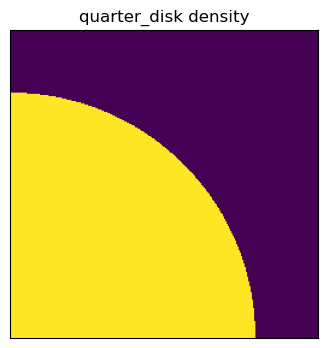

In [3]:
if TARGET_NAME == "image":
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    show_image_target(iio.imread(IMAGE_PATH), ax=axes[0], title="input image")
    plot_density(target, resolution=256, device=DEVICE, ax=axes[1], title="normalized density")
    fig.tight_layout()
else:
    plot_density(target, resolution=256, device=DEVICE)
    plt.show()

## Load Discrepancy Tables

In [4]:
series = {}

optimized_discrepancy_path = OPTIMIZED_DIR / "discrepancies.npz"
if optimized_discrepancy_path.exists():
    series["optimized"] = load_discrepancies(optimized_discrepancy_path)
else:
    print(f"Missing optimized discrepancies: {optimized_discrepancy_path}")

for method in BASELINE_METHODS:
    path = BASELINES_DIR / f"{method}_discrepancies.npz"
    if path.exists():
        series[method] = load_discrepancies(path)
    else:
        print(f"Missing baseline discrepancies: {path}")

list(series.keys())

['optimized',
 'random_base',
 'sobol_base',
 'sobol_shifted',
 'sobol_scrambled',
 'halton_base',
 'halton_shifted',
 'halton_scrambled']

## Discrepancy Curves

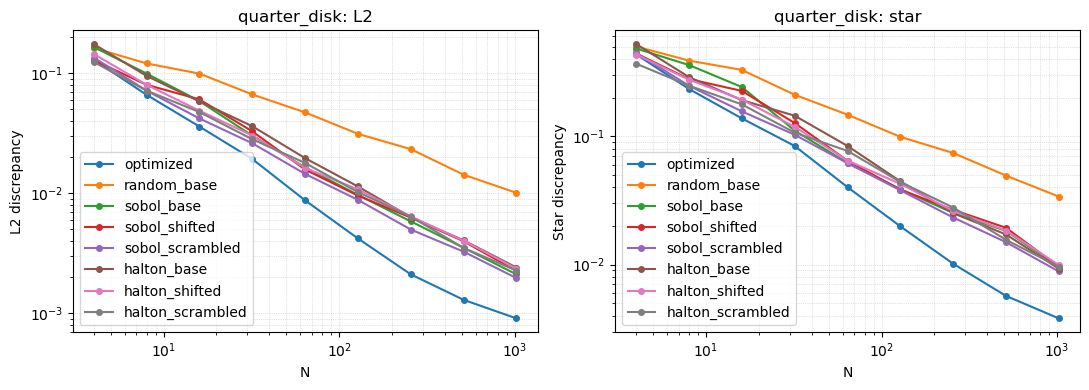

In [5]:
if series:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    plot_discrepancy_curves(series, metric="l2_mean", ax=axes[0], title=f"{TARGET_NAME}: L2")
    plot_discrepancy_curves(series, metric="star_mean", ax=axes[1], title=f"{TARGET_NAME}: star")
    fig.tight_layout()
else:
    print("No discrepancy files found.")

## Point Sets

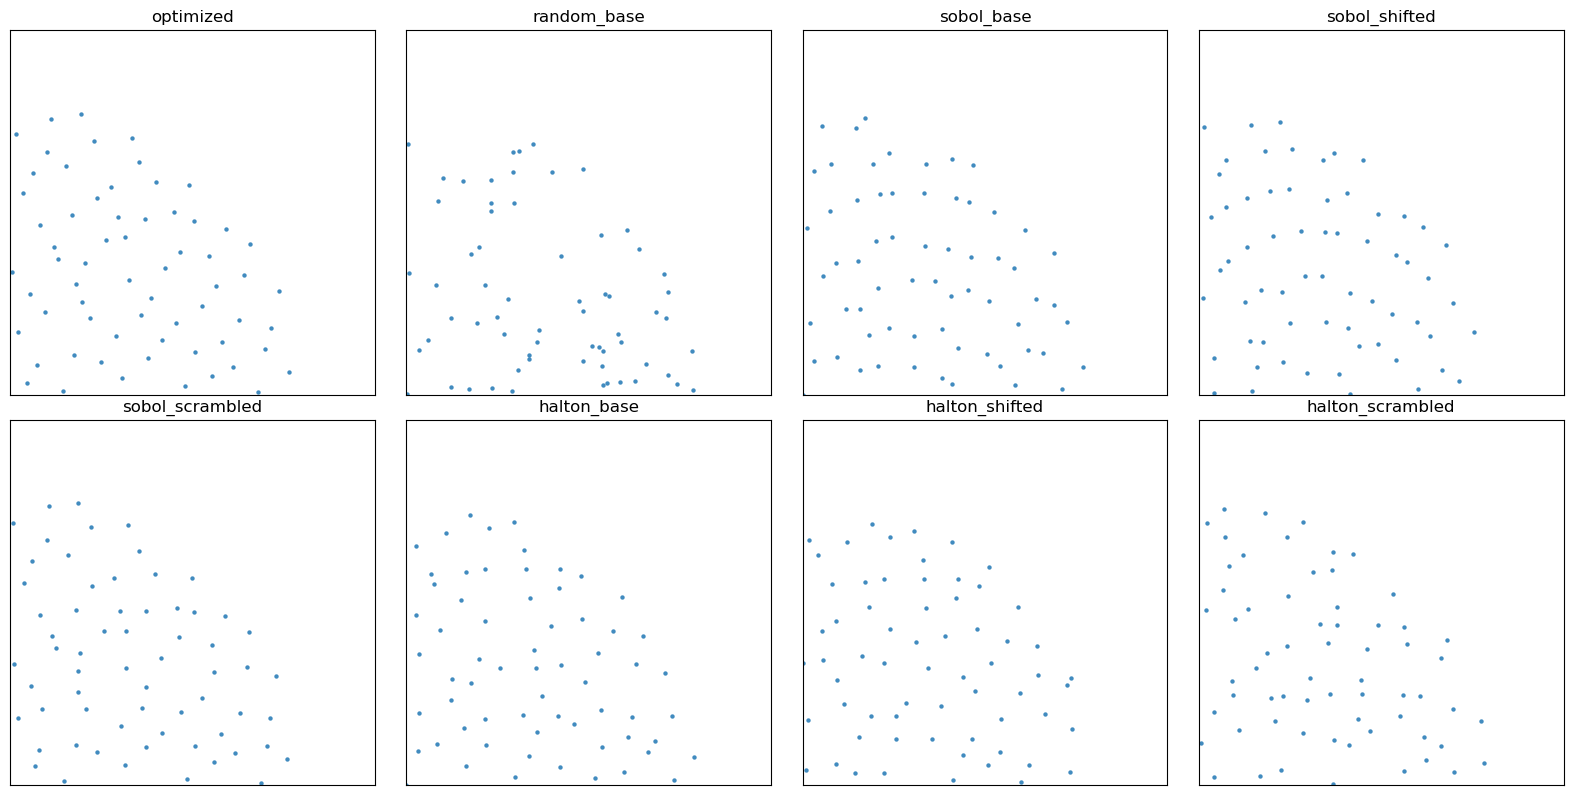

In [6]:
point_sets = {}

optimized_points_path = OPTIMIZED_DIR / f"points_n{N}.npz"
if optimized_points_path.exists():
    point_sets["optimized"] = load_point_sets(optimized_points_path)["points"][0]
else:
    print(f"Missing optimized points: {optimized_points_path}")

for method in BASELINE_METHODS:
    path = BASELINES_DIR / f"{method}_points_n{N}.npz"
    if path.exists():
        point_sets[method] = load_point_sets(path)["points"][0]

if point_sets:
    plot_point_sets_grid(point_sets, max_columns=4, marker_size=10)
else:
    print("No point-set files found for this N.")